# 03 · Sleep debt

Target is 7.5 h a night. Debt is the shortfall summed over the last 14 nights;
missing nights are scaled from the logged nights in the same window rather than counted as rest.

In [1]:
from sleep_patterns.clean import nightly
from sleep_patterns.io import load_sleep
from sleep_patterns.metrics import sleep_debt
from sleep_patterns import plots

nights = nightly(load_sleep())
debt = sleep_debt(nights, target=7.5, window=14)
debt.describe().round(2)

,deficit,debt,cumulative
count,353.00,359.00,365.00
mean,0.61,8.57,113.11
std,0.93,5.69,61.58
min,-1.95,-1.01,0.53
25%,0.00,4.87,61.63
50%,0.62,7.09,132.57
75%,1.25,11.81,156.78
max,3.53,22.30,215.40


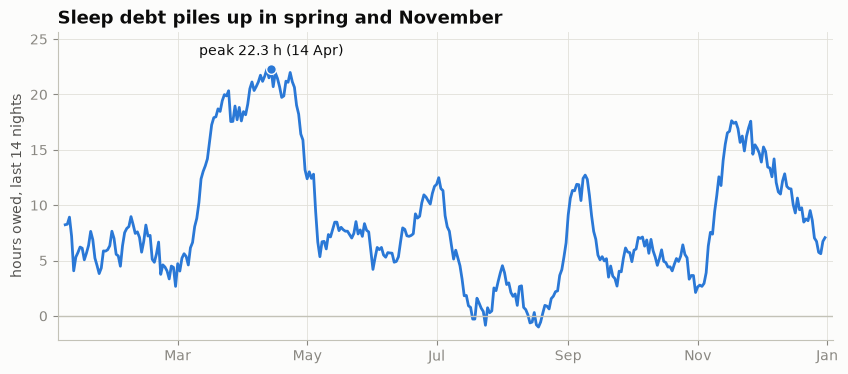

In [2]:
plots.debt_line(debt, title="Sleep debt piles up in spring and November");

In [3]:
monthly = debt["deficit"].groupby(debt.index.to_period("M")).agg(["mean", "sum", "count"])
monthly.columns = ["mean_deficit_h", "total_deficit_h", "nights_logged"]
monthly.round(2)

,mean_deficit_h,total_deficit_h,nights_logged
night,,,
2025-01,0.46,13.78,30
2025-02,0.37,9.70,26
2025-03,1.18,35.37,30
2025-04,1.28,36.98,29
2025-05,0.51,15.87,31
2025-06,0.68,20.27,30
2025-07,0.21,6.28,30
2025-08,0.18,5.47,30
2025-09,0.46,12.92,28


Two clear humps: mid-March to late April (exams) and November (end-of-year deadlines).
July and August are the only stretch where I actually pay the debt back.
The year-end cumulative number is not very meaningful on its own — it almost only goes up
at a 7.5 h target, since I rarely beat it — but its *slope* tells the same story:

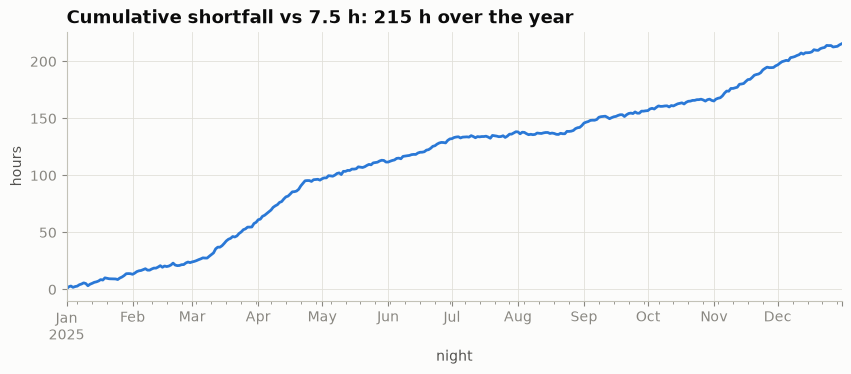

In [4]:
ax = debt["cumulative"].plot(figsize=(10, 3.5), color=plots.BLUE)
ax.set_ylabel("hours")
ax.set_title(f"Cumulative shortfall vs 7.5 h: {debt['cumulative'].iloc[-1]:.0f} h over the year");